# Survey ways to define multi-element materials

<!-- index:description -->
Explore ways of defining multi-element materials in OpenMC.
<!-- /index:description -->

<!-- generated:structure -->
```text
Survey ways to define multi-element materials
├── 1. The typical way
├── 2. The programmatic way
├── 3. From the PNNL JSON
├── 4. With `neutronics_material_maker`
│   └── A closer look
└── Summary
```
<!-- /generated:structure -->

This notebook explores four ways of defining multi-element materials in OpenMC.
The focus is on how to define materials, not on comparing their compositions
or densities. All cross-sections are at 294 K.

The four approaches produce `mats_typic` (manual), `mats_prog`
(DataFrame), `mats_nat` (PNNL JSON), and `mats_nmm`
(`neutronics_material_maker`), respectively.

In [1]:
import openmc
import matplotlib.pyplot as plt

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml


def plotxs(dic):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, (name, mat) in zip(axes, dic.items()):
        openmc.plot_xs(
            reactions={mat: ['total']},
            axis=ax,
        )
        ax.set_title(name)
        ax.get_legend().remove()
        ax.lines[-1].set(color='g', marker='.', ls='None', ms=1)

    fig.tight_layout()

## 1. The typical way

In [2]:
steel = openmc.Material(name='Steel, Stainless 316L')
steel.add_element('C', 0.001384)
steel.add_element('Mn', 0.020165)
steel.add_element('P', 0.000805)
steel.add_element('S', 0.000518)
steel.add_element('Si', 0.019722)
steel.add_element('Cr', 0.181098)
steel.add_element('Ni', 0.113247)
steel.add_element('Mo', 0.014432)
steel.add_element('Fe', 0.648629)
steel.set_density('g/cm3', 8.0)

concrete = openmc.Material(name='Concrete, Ordinary (NIST)')
concrete.add_element('H', 0.305322)
concrete.add_element('C', 0.002880)
concrete.add_element('O', 0.500411)
concrete.add_element('Na', 0.009212)
concrete.add_element('Mg', 0.000725)
concrete.add_element('Al', 0.010298)
concrete.add_element('Si', 0.151046)
concrete.add_element('K', 0.003578)
concrete.add_element('Ca', 0.014924)
concrete.add_element('Fe', 0.001605)
concrete.set_density('g/cm3', 2.3)

polyethylene = openmc.Material(name='Polyethylene, Borated')
polyethylene.add_element('H', 0.627756)
polyethylene.add_element('B', 0.046680)
polyethylene.add_element('C', 0.325564)
polyethylene.set_density('g/cm3', 1.0)

mats_typic = {
    mat.name: mat for mat in [steel, concrete, polyethylene]
}

openmc.Materials(mats_typic.values())

[Material
 	ID             =	1
 	Name           =	Steel, Stainless 316L
 	Temperature    =	None
 	Density        =	8.0 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	C12            =	0.001368668048 [ao]
 	C13            =	1.5331952e-05 [ao]
 	Mn55           =	0.020165     [ao]
 	P31            =	0.000805     [ao]
 	S32            =	0.0004923110332 [ao]
 	S33            =	3.8782142e-06 [ao]
 	S34            =	2.17352282e-05 [ao]
 	S36            =	7.55244e-08  [ao]
 	Si28           =	0.0181895374896 [ao]
 	Si29           =	0.0009236128152 [ao]
 	Si30           =	0.0006088496952 [ao]
 	Cr50           =	0.007868708100000002 [ao]
 	Cr52           =	0.15174020322 [ao]
 	Cr53           =	0.01720612098 [ao]
 	Cr54           =	0.0042829677 [ao]
 	Ni58           =	0.077095046943 [ao]
 	Ni60           =	0.029696874057 [ao]
 	Ni61           =	0.001290902553 [ao]
 	Ni62           =	0.004115962215 [ao]
 	Ni64           =	0.001048214232 [ao]
 	M

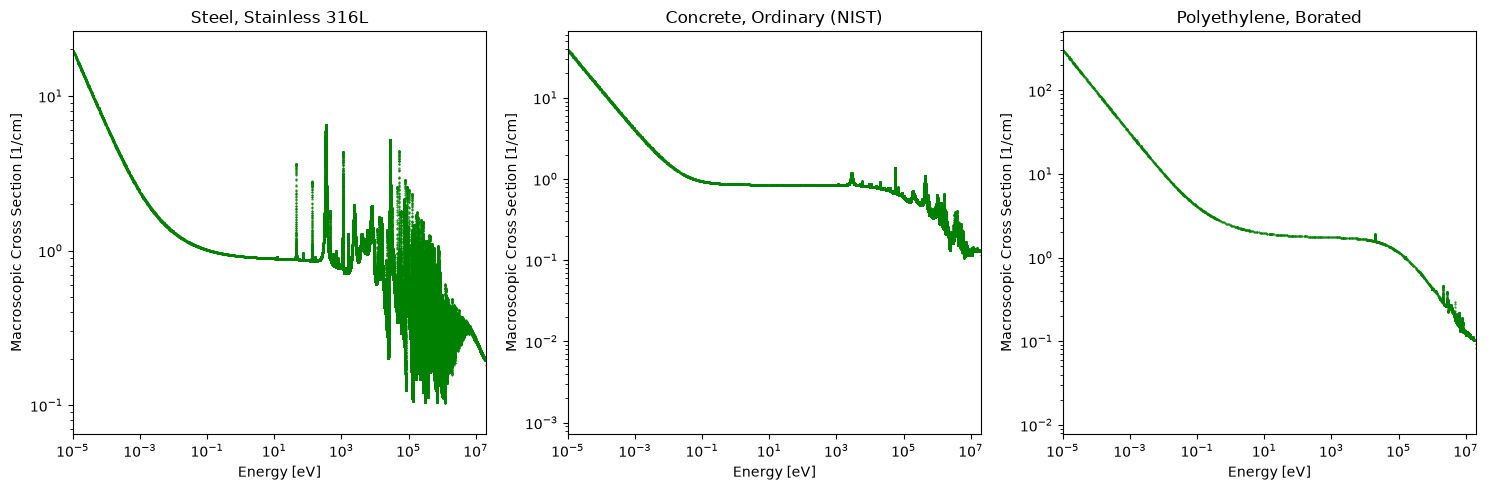

In [3]:
plotxs(mats_typic)

## 2. The programmatic way

This is generally the preferred approach in the OpenMC Workbench.
Keeping the input compositions in a DataFrame minimizes repetitive code,
reduces the risk of inconsistencies, and makes the data easier to explore,
modify, and validate. A single loop can create many materials without
repeating `add_element()` calls. The values remain explicit, rather than
being hidden inside an external material library.

In [4]:
import pandas as pd

# Atomic fractions (ao).
compositions_ao = {
    'Steel, Stainless 316L': {
        'C': 0.001384,
        'Mn': 0.020165,
        'P': 0.000805,
        'S': 0.000518,
        'Si': 0.019722,
        'Cr': 0.181098,
        'Ni': 0.113247,
        'Mo': 0.014432,
        'Fe': 0.648629,
    },
    'Concrete, Ordinary (NIST)': {
        'H': 0.305322,
        'C': 0.002880,
        'O': 0.500411,
        'Na': 0.009212,
        'Mg': 0.000725,
        'Al': 0.010298,
        'Si': 0.151046,
        'K': 0.003578,
        'Ca': 0.014924,
        'Fe': 0.001605,
    },
    'Polyethylene, Borated': {
        'H': 0.627756,
        'B': 0.046680,
        'C': 0.325564,
    },
}

# Use column names matching the arguments of openmc.Material.add_element():
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Material.html
# The next cell passes these as keyword arguments. For example,
# renaming 'percent' to 'fraction' would raise an error:
# TypeError: Material.add_element() got an unexpected keyword
# argument 'fraction'.
mats_df = pd.DataFrame(columns=['name', 'element', 'percent'])

for name, composition_ao in compositions_ao.items():
    for element, fraction in composition_ao.items():
        mats_df.loc[len(mats_df)] = [name, element, fraction]

mats_df

,name,element,percent
0,"Steel, Stainless 316L",C,0.001384
1,"Steel, Stainless 316L",Mn,0.020165
2,"Steel, Stainless 316L",P,0.000805
3,"Steel, Stainless 316L",S,0.000518
4,"Steel, Stainless 316L",Si,0.019722
5,"Steel, Stainless 316L",Cr,0.181098
6,"Steel, Stainless 316L",Ni,0.113247
7,"Steel, Stainless 316L",Mo,0.014432
8,"Steel, Stainless 316L",Fe,0.648629
9,"Concrete, Ordinary (NIST)",H,0.305322


In [5]:
# Define the elemental composition.
mats_prog = {}
for name, dat in mats_df.groupby('name'):
    mats_prog[name] = openmc.Material(name=name)

    for _, row in dat.drop(columns='name').iterrows():
        mats_prog[name].add_element(**row.dropna().to_dict())

In [6]:
# Define the density.
densities = {
    'Steel, Stainless 316L': 8.0,
    'Concrete, Ordinary (NIST)': 2.3,
    'Polyethylene, Borated': 1.0,
}

for name, density in densities.items():
    mats_prog[name].set_density('g/cm3', density)
openmc.Materials(mats_prog.values())
# Three OpenMC materials successfully created.

[Material
 	ID             =	4
 	Name           =	Concrete, Ordinary (NIST)
 	Temperature    =	None
 	Density        =	2.3 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	H1             =	0.30527444915172 [ao]
 	H2             =	4.755084828e-05 [ao]
 	C12            =	0.00284809536 [ao]
 	C13            =	3.190464e-05 [ao]
 	O16            =	0.49922032206660005 [ao]
 	O17            =	0.00018965576900000002 [ao]
 	O18            =	0.0010010221644 [ao]
 	Na23           =	0.009212     [ao]
 	Mg24           =	0.00057239475 [ao]
 	Mg25           =	7.264499999999999e-05 [ao]
 	Mg26           =	7.996024999999999e-05 [ao]
 	Al27           =	0.010298     [ao]
 	Si28           =	0.13930924245280002 [ao]
 	Si29           =	0.007073725853600001 [ao]
 	Si30           =	0.0046630316936 [ao]
 	K39            =	0.003336774818 [ao]
 	K40            =	4.18626e-07  [ao]
 	K41            =	0.000240806556 [ao]
 	Ca40           =	0.01446747484 [ao]
 	Ca

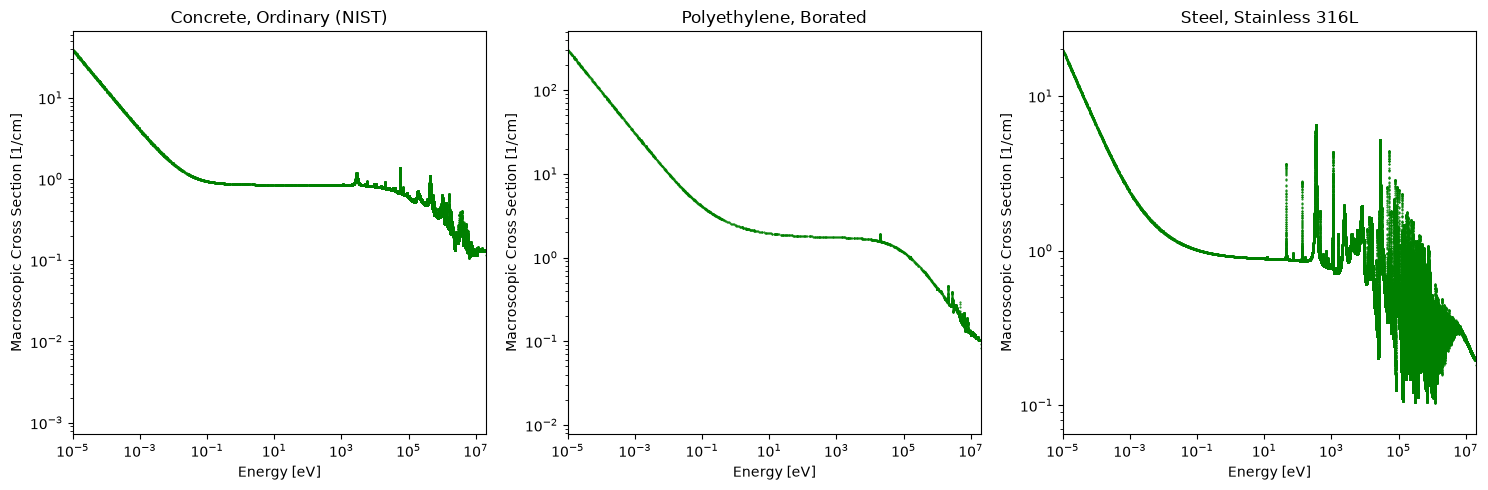

In [7]:
plotxs(mats_prog)

## 3. From the PNNL JSON

The [PNNL Rev. 2 material library](https://github.com/openmc-dev/openmc/blob/develop/openmc/data/material_libraries/pnnl_v2.json)
provides elemental atomic fractions and reference densities. Download it once,
then set `download_pnnl = False` to reuse the file saved under `DATA_ROOT`.

This library is currently available in OpenMC's **untagged `develop` branch**
(after version 0.16.0). The next tagged release, expected to be **0.16.1**,
should streamline this approach through `openmc.Material.from_library()`.
Here, we read the JSON directly, so a development installation isn't needed.

In [8]:
import json
import subprocess

pnnl_url = (
    'https://raw.githubusercontent.com/openmc-dev/openmc/'
    'develop/openmc/data/material_libraries/pnnl_v2.json'
)
pnnl_file = DATA_ROOT / 'pnnl_v2.json'
download_pnnl = True  # Set False to reuse the downloaded file.

if download_pnnl:
    subprocess.run(
        ['curl', '-fLsS', '-o', str(pnnl_file), pnnl_url],
        check=True,
    )

if not pnnl_file.is_file():
    raise FileNotFoundError(
        f'{pnnl_file} is missing. Set download_pnnl = True.'
    )

with pnnl_file.open() as f:
    pnnl = json.load(f)

In [9]:
mats_nat = {}

for name in compositions_ao:
    data = pnnl['materials'][name]
    mat = openmc.Material(name=name)

    for element, fraction in data['elements'].items():
        mat.add_element(
            element,
            fraction,
            percent_type=pnnl['percent_type'],
        )

    mat.set_density(pnnl['density_units'], data['density'])
    mats_nat[name] = mat

openmc.Materials(mats_nat.values())

[Material
 	ID             =	7
 	Name           =	Steel, Stainless 316L
 	Temperature    =	None
 	Density        =	8.0 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	C12            =	0.001368668048 [ao]
 	C13            =	1.5331952e-05 [ao]
 	Mn55           =	0.020165     [ao]
 	P31            =	0.000805     [ao]
 	S32            =	0.0004923110332 [ao]
 	S33            =	3.8782142e-06 [ao]
 	S34            =	2.17352282e-05 [ao]
 	S36            =	7.55244e-08  [ao]
 	Si28           =	0.0181895374896 [ao]
 	Si29           =	0.0009236128152 [ao]
 	Si30           =	0.0006088496952 [ao]
 	Cr50           =	0.007868708100000002 [ao]
 	Cr52           =	0.15174020322 [ao]
 	Cr53           =	0.01720612098 [ao]
 	Cr54           =	0.0042829677 [ao]
 	Ni58           =	0.077095046943 [ao]
 	Ni60           =	0.029696874057 [ao]
 	Ni61           =	0.001290902553 [ao]
 	Ni62           =	0.004115962215 [ao]
 	Ni64           =	0.001048214232 [ao]
 	M

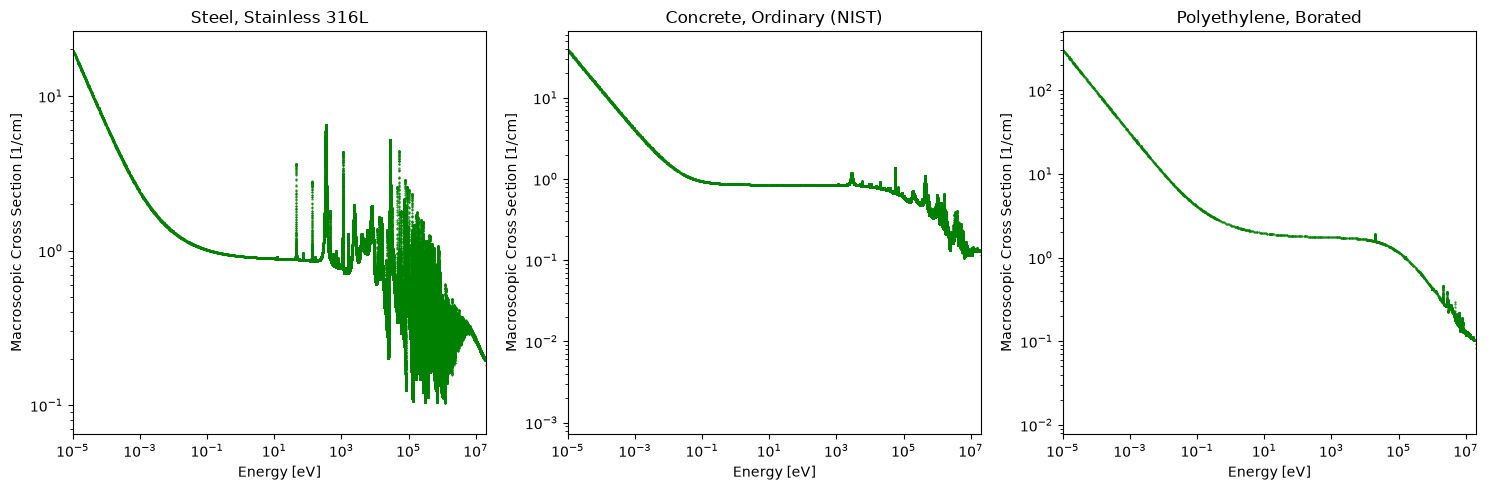

In [10]:
plotxs(mats_nat)

## 4. With `neutronics_material_maker`

In [11]:
import neutronics_material_maker as nmm

available = nmm.AvailableMaterials()
list(available)

['WC',
 'WB',
 'SiC',
 'eurofer',
 'SS_316L_N_IG',
 'tungsten_with_impurities',
 'tungsten',
 'P91',
 'SST91',
 'concrete_ordinary',
 'concrete_heavy',
 'concrete_boronated_heavy',
 'a36_steel',
 'CuCrZr_with_impurities',
 'CuCrZr',
 'Ti-6Al-4V',
 'epoxy_resin',
 'zircaloy_4',
 'Rexolite 1422',
 'ej-200-plastic-scintillator',
 'ej-204-plastic-scintillator',
 'ej-208-plastic-scintillator',
 'ej-212-plastic-scintillator',
 'A-150 Tissue-Equivalent Plastic',
 'Acetone',
 'Acetylene',
 'Air (dry, near sea level)',
 'Alanine',
 'Aluminum',
 'Aluminum Oxide',
 'Aluminum, alloy 2024-O',
 'Aluminum, alloy 2090-T83',
 'Aluminum, alloy 3003',
 'Aluminum, alloy 4043-O',
 'Aluminum, alloy 5086-O',
 'Aluminum, alloy 6061-O',
 'Aluminum, alloy 7075-O',
 'Ammonia (liquid at T= -79 C)',
 'Anthracene',
 'Argon',
 'Asbestos (Chrysotile)',
 'Asphalt',
 'Asphalt pavement',
 'Bakelite',
 'Barium Fluoride',
 'Barium sulfate',
 'Benzene',
 'Beryllium',
 'Beryllium Carbide',
 'Beryllium Oxide',
 'Bismuth',
 '

In [12]:
mats_nmm = {}

for name in compositions_ao:
    mat = nmm.Material.from_library(name=name).openmc_material
    mats_nmm[name] = mat

openmc.Materials(mats_nmm.values())

[Material
 	ID             =	11
 	Name           =	Steel, Stainless 316L
 	Temperature    =	None
 	Density        =	8.0 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	C12            =	0.001368668048 [ao]
 	C13            =	1.5331952e-05 [ao]
 	Cr50           =	0.007868708100000002 [ao]
 	Cr52           =	0.15174020322 [ao]
 	Cr53           =	0.01720612098 [ao]
 	Cr54           =	0.0042829677 [ao]
 	Fe54           =	0.03791236505 [ao]
 	Fe56           =	0.59514305266 [ao]
 	Fe57           =	0.01374444851 [ao]
 	Fe58           =	0.00182913378 [ao]
 	Mn55           =	0.020165     [ao]
 	Mo100          =	0.0014062540800000001 [ao]
 	Mo92           =	0.00211414368 [ao]
 	Mo94           =	0.00132586784 [ao]
 	Mo95           =	0.0022907913600000002 [ao]
 	Mo96           =	0.00240624736 [ao]
 	Mo97           =	0.00138287424 [ao]
 	Mo98           =	0.00350582144 [ao]
 	Ni58           =	0.077095046943 [ao]
 	Ni60           =	0.029696874057 [

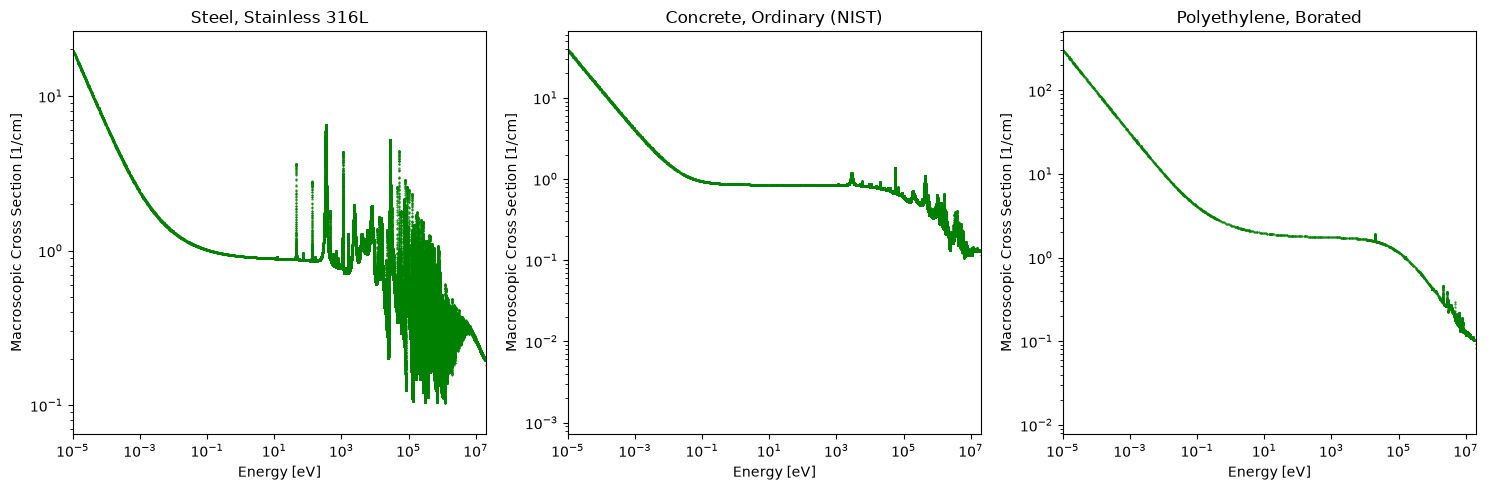

In [13]:
plotxs(mats_nmm)

### A closer look

NMM's material library stores densities as numerical values or string
expressions. The latter are evaluated using `asteval`, with CoolProp
used for expressions starting with `PropsSI`. The implementation
identifies temperature and pressure dependencies by searching for
these substrings in the expressions, rather than using explicit
dependency flags.

Source: [NMM `material.py`, lines 699–729](https://github.com/fusion-energy/neutronics_material_maker/blob/main/src/neutronics_material_maker/material.py#L699-L729).

In [14]:
mats = ['lithium-lead', 'FLiBe', 'Lithium', 'H2O']
for mat in mats:
    for kk, vv in available[mat].items():
        print('{:20s} {}'.format(kk, vv))
    print()

chemical_equation    Pb842Li158
density              99.90*(0.1-16.8e-6*(temperature - 273.15))
density_unit         g/cm3
comment              density equation valid for in the range 240-350 C. source http://aries.ucsd.edu/LIB/PROPS/PANOS/lipb.html
percent_type         ao
enrichment_target    Li6
enrichment_type      ao

chemical_equation    F2Li2BeF2
density              2.214 - 4.2e-4 * (temperature - 273.15)
density_unit         g/cm3
comment              source http://aries.ucsd.edu/LIB/MEETINGS/0103-TRANSMUT/gohar/Gohar-present.pdf
percent_type         ao
enrichment_target    Li6
enrichment_type      ao

density              0.534
density_unit         g/cm3
percent_type         ao
comment              https://www.pnnl.gov/main/publications/external/technical_reports/PNNL-15870Rev2.pdf
elements             {'Li': 1}

chemical_equation    H2O
density              PropsSI('D', 'T', temperature, 'P', pressure, 'Water')/1000.
density_unit         g/cm3
comment              CoolProp py

In [15]:
for mat in mats:
    density = available[mat]['density']
    material = nmm.Material.from_library(
        name=mat,
        temperature=294,
        pressure=1e5,
    ).openmc_material
    mass_density = material.get_mass_density()

    print(mat)
    print(f'  NMM density ({type(density).__name__}): {density}')
    print(f'  At 294 K, 1 bar: {mass_density:.6f} g/cm³')
    print()

lithium-lead
  NMM density (str): 99.90*(0.1-16.8e-6*(temperature - 273.15))
  At 294 K, 1 bar: 9.955007 g/cm³

FLiBe
  NMM density (str): 2.214 - 4.2e-4 * (temperature - 273.15)
  At 294 K, 1 bar: 2.205243 g/cm³

Lithium
  NMM density (float): 0.534
  At 294 K, 1 bar: 0.534000 g/cm³

H2O
  NMM density (str): PropsSI('D', 'T', temperature, 'P', pressure, 'Water')/1000.
  At 294 K, 1 bar: 0.998027 g/cm³



## Summary

| Dictionary | Method | Advantages and limitations |
|---|---|---|
| `mats_typic` | Individual `add_element()` calls | Explicit but repetitive |
| `mats_prog` | DataFrame and loop | Consistent and reusable |
| `mats_nat` | PNNL JSON | Native API planned for 0.16.1 |
| `mats_nmm` | NMM library | Fusion materials; extra dependency |

The programmatic approach is preferred in this Workbench. It is more
consistent and less error-prone than individual `add_element()` calls,
and easier to organize, modify, extend, and reuse.